# Assignment 8: Gaussian Discriminant Analysis (LDA and QDA) on Iris Dataset
**Aim:** Implement Linear Discriminant Analysis (LDA) and Quadratic Discriminant Analysis (QDA) classifiers using Scikit-Learn, evaluate their classification accuracies, and plot class distributions to verify Gaussian assumptions.  
**Tools / Libraries:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`  
**Programming Platform / Language:** Jupyter Notebook, Python

## Theory & Task Overview

### Gaussian Discriminant Analysis (GDA)
GDA is a generative supervised classification algorithm that assumes the continuous predictor features follow a multivariate Gaussian (normal) distribution for each class.
* **Linear Discriminant Analysis (LDA):** Assumes that all classes share a common covariance matrix ($\Sigma_k = \Sigma$). This results in a *linear* decision boundary.
* **Quadratic Discriminant Analysis (QDA):** Allows each class to have its own unique covariance matrix ($\Sigma_k$). This results in a *quadratic/non-linear* decision boundary.
* **Gaussian Distribution Check:** Visualizing feature distributions via density plots (KDE/Histograms) helps evaluate whether the dataset features approximate a bell-shaped normal distribution per class.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report

# 1. Load the Iris dataset
df = pd.read_csv('iris_dataset_GDA.csv')

# 2. Separate features (X) and target/species (y)
X = df.iloc[:, :-1]  # Features: Sepal and Petal lengths/widths
y = df.iloc[:, -1]   # Target: Species

# 3. Split data into training (80%) and testing (20%) sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dataset loaded and split successfully!")
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

Dataset loaded and split successfully!
Training samples: 120 | Testing samples: 30


---
## Part 1: Linear Discriminant Analysis (LDA)

In [3]:
# Initialize and train LDA
lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train, y_train)

# Predict and evaluate
y_pred_lda = lda_model.predict(X_test)
acc_lda = accuracy_score(y_test, y_pred_lda)

print("=" * 45)
print("       LINEAR DISCRIMINANT ANALYSIS (LDA)       ")
print("=" * 45)
print(f"LDA Accuracy : {acc_lda * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lda))

       LINEAR DISCRIMINANT ANALYSIS (LDA)       
LDA Accuracy : 100.00%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



---
## Part 2: Quadratic Discriminant Analysis (QDA)

In [4]:
# Initialize and train QDA
qda_model = QuadraticDiscriminantAnalysis()
qda_model.fit(X_train, y_train)

# Predict and evaluate
y_pred_qda = qda_model.predict(X_test)
acc_qda = accuracy_score(y_test, y_pred_qda)

print("=" * 45)
print("      QUADRATIC DISCRIMINANT ANALYSIS (QDA)     ")
print("=" * 45)
print(f"QDA Accuracy : {acc_qda * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_qda))

      QUADRATIC DISCRIMINANT ANALYSIS (QDA)     
QDA Accuracy : 100.00%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



---
## Part 3: Class Distribution Plot (Gaussian Assumption Check)
We use a pairplot with Kernel Density Estimation (KDE) to inspect whether the features for each class follow a normal (Gaussian) distribution.

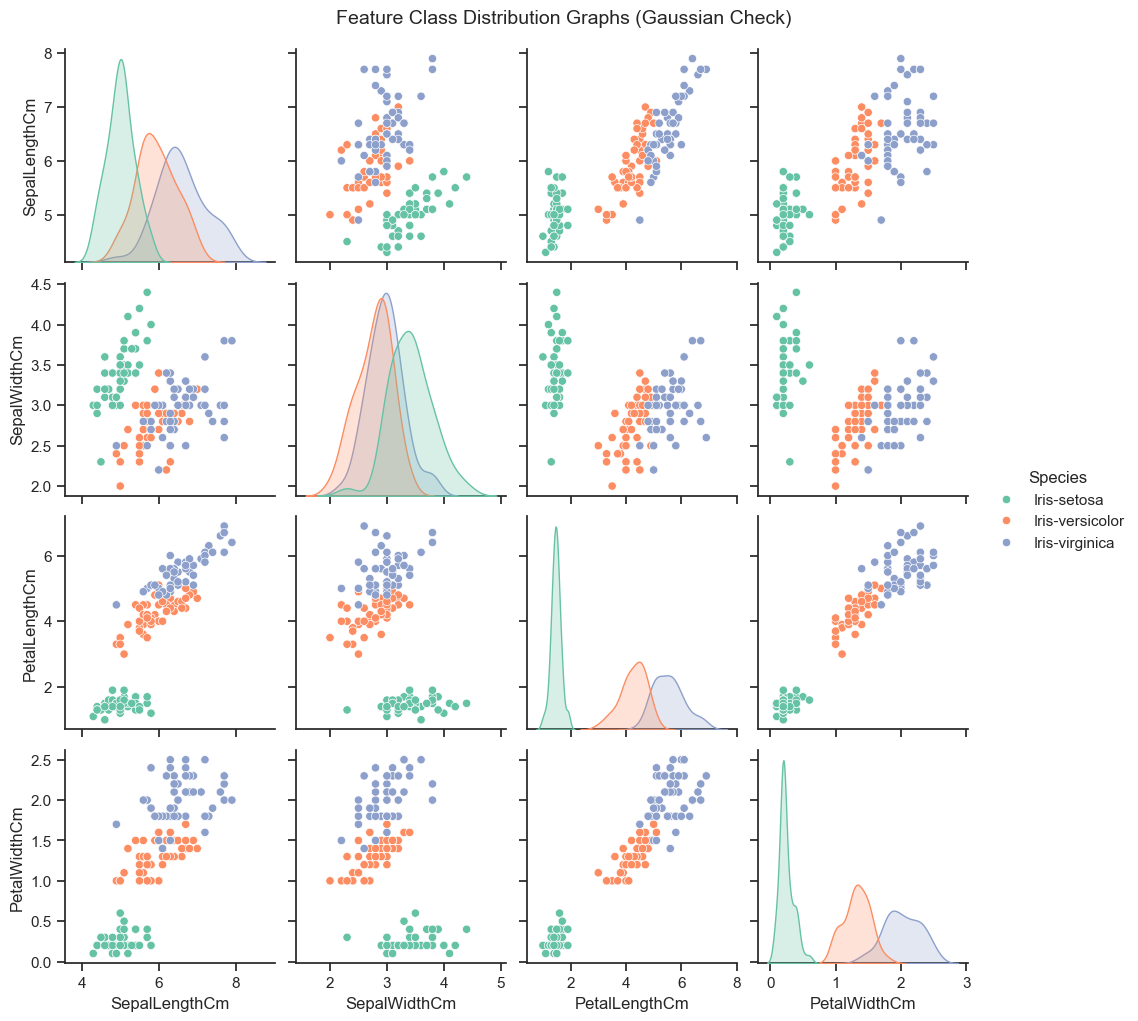

In [5]:
# Set plot style
sns.set_theme(style="ticks")

# Create a pairplot to visualize feature distributions and separation across classes
g = sns.pairplot(df, hue="Species", diag_kind="kde", palette="Set2")
g.fig.suptitle("Feature Class Distribution Graphs (Gaussian Check)", y=1.02, fontsize=14)

plt.show()

## Interpretation of Results & Gaussian Compliance

1. **Accuracy Comparison:** 
   * Both LDA and QDA typically perform exceptionally well on the Iris dataset (often achieving 96% to 100% accuracy), because the classes are relatively distinct and well-behaved.
2. **Gaussian Distribution Compliance:**
   * Looking at the diagonal KDE plots generated above, features like *Petal Length* and *Petal Width* display clear, unimodal bell-shaped curves for each species, confirming that they closely adhere to a Gaussian distribution.
   * This strong adherence to normality validates the high effectiveness of Gaussian Discriminant Analysis models (LDA and QDA) on this dataset.